<a href="https://colab.research.google.com/github/PalQuisp/Sis420-int/blob/main/lab06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/)


# PyTorch - Regresión y Clasificación
### Reimplementación de Laboratorios con División Manual de Datos (80% Train / 20% Test) y Descenso por Gradiente Manual


Hasta ahora hemos implementado nuestros propios modelos de Machine Learning desde cero utilizando `NumPy` y operaciones matriciales manuales.
En este cuadernillo reimplementaremos todos los laboratorios anteriores utilizando la librería **PyTorch**.

A diferencia del uso de librerías automáticas:
1. **División Manual de Datos**: Realizamos la separación de datasets en **80% Entrenamiento (Train)** y **20% Prueba (Test)** de forma manual utilizando permutaciones e indexación de NumPy, sin requerir `train_test_split`.
2. **Hiperparámetros Separados**: Definimos explícitamente las variables de configuración (`learning_rate`, `epochs`) antes de cada proceso de entrenamiento.
3. **Descenso por Gradiente Manual**: Realizamos la actualización directa de parámetros (`with torch.no_grad(): param -= lr * param.grad`) sin utilizar la librería `torch.optim`.


> Si trabajas en Google Colab ya tendrás `PyTorch` instalado. Si trabajas localmente, asegúrate de tener instalados `torch`, `numpy`, `pandas`, `scikit-learn` y `matplotlib`.


## 1. ¿Qué es PyTorch?
Una forma sencilla de entender qué es PyTorch es la siguiente:
$$\text{PyTorch} = \text{NumPy} + \text{Autograd} + \text{Soporte GPU}$$
1. **Tensores matriciales**: Estructuras multidimensionales equivalentes a los arrays de NumPy.
2. **Autograd**: Motor de diferenciación automática que calcula gradientes exactos mediante la regla de la cadena.
3. **Aceleración por Hardware**: Capacidad de ejecutar operaciones en GPU (CUDA) o MPS sin cambiar la sintaxis.


In [79]:
# 1. Configuración del Entorno e Importaciones
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# Seleccionar dispositivo (GPU si está disponible, de lo contrario CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo en uso: {device}')
print(f'Versión de PyTorch: {torch.__version__}')


Dispositivo en uso: cpu
Versión de PyTorch: 2.11.0+cpu


## 2. Conceptos Clave: Autograd
La funcionalidad más importante de PyTorch es `Autograd`. Al crear un tensor con `requires_grad=True`, PyTorch registra todas las operaciones realizadas sobre él para calcular derivadas automáticas al llamar `.backward()`.


In [80]:
# Ejemplo de diferenciación automática con Autograd
w = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)
x = torch.tensor(3.0)

# Operaciones: y = w * x + b
y = w * x + b
y.backward()  # Calcular gradientes dy/dw y dy/db

print(f'Derivada dy/dw (esperada 3.0): {w.grad.item()}')
print(f'Derivada dy/db (esperada 1.0): {b.grad.item()}')


Derivada dy/dw (esperada 3.0): 3.0
Derivada dy/db (esperada 1.0): 1.0


## 3. Regresión Lineal Simple (Lab 1)
Abordamos el problema de predecir una variable continua $y$ a partir de una única variable explicativa $x$.
Ajustamos la función lineal: $y = w \cdot x + b$.
Dividimos manualmente el dataset en **80% Entrenamiento** y **20% Prueba**.


In [81]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [82]:
# Cargar el dataset de regresión simple
data = pd.read_csv('/content/drive/MyDrive/machine learning/laboratorio/regsimple.csv')

df_simple = data

print(f'Total de muestras en el dataset: {len(df_simple)}')
df_simple.head()


Total de muestras en el dataset: 23100


,appid,name,developer,publisher,positive,negative,owners,average_forever,average_2weeks,median_forever,...,short_description,supported_languages,platforms_windows,platforms_mac,platforms_linux,metacritic_score,recommendations,achievements,genres,categories
0,730,Counter-Strike: Global Offensive,Valve,Valve,7642084,1173003,"100,000,000 .. 200,000,000",0,0,0,...,"For over two decades, Counter-Strike has offer...","Czech, Danish, Dutch, English<strong>*</strong...",True,False,True,NaN,5211693.0,1.0,"Action, Free To Play","Multi-player, Cross-Platform Multiplayer, Stea..."
1,1172470,Apex Legends,Respawn,Electronic Arts,668053,326926,"100,000,000 .. 200,000,000",0,0,0,...,"Apex Legends is the award-winning, free-to-pla...","English<strong>*</strong>, French<strong>*</st...",True,False,False,88.0,1580.0,12.0,"Action, Adventure, Free To Play","Multi-player, PvP, Online PvP, Co-op, Online C..."
2,578080,PUBG: BATTLEGROUNDS,PUBG Corporation,"KRAFTON, Inc.",1520457,1037487,"100,000,000 .. 200,000,000",0,0,0,...,"PUBG: BATTLEGROUNDS, the high-stakes winner-ta...","English, Korean, Simplified Chinese, French, G...",True,False,False,NaN,1762488.0,37.0,"Action, Adventure, Massively Multiplayer, Free...","Multi-player, PvP, Online PvP, Custom Volume C..."
3,1623730,Palworld,Pocketpair,Pocketpair,358266,22443,"50,000,000 .. 100,000,000",0,0,0,...,"Fight, farm, build and work alongside mysterio...","English, Simplified Chinese, Traditional Chine...",True,False,False,NaN,397504.0,75.0,"Action, Adventure, Indie, RPG","Single-player, Multi-player, Co-op, Online Co-..."
4,440,Team Fortress 2,Valve,Valve,1044264,117208,"50,000,000 .. 100,000,000",0,0,0,...,Nine distinct classes provide a broad range of...,"English<strong>*</strong>, Danish, Dutch, Finn...",True,False,True,92.0,47647.0,520.0,"Action, Free To Play","Multi-player, Cross-Platform Multiplayer, Stea..."


In [83]:
# Proceso de División Manual de Datos (80% Train / 20% Test) sin librerías externas
X_simple = df_simple[['positive']].values
y_simple = df_simple[['negative']].values

# Permutación aleatoria de índices para asegurar distribución uniforme
np.random.seed(42)
total_samples = len(X_simple)
train_ratio = 0.8
train_size = int(total_samples * train_ratio)

indices = np.random.permutation(total_samples)
train_idx = indices[:train_size]
test_idx = indices[train_size:]

# Separación de conjuntos mediante indexación manual de NumPy
X_train_s, y_train_s = X_simple[train_idx], y_simple[train_idx]
X_test_s, y_test_s = X_simple[test_idx], y_simple[test_idx]

print(f'Muestras de Entrenamiento (Train 80%): {len(X_train_s)}')
print(f'Muestras de Prueba (Test 20%): {len(X_test_s)}')


Muestras de Entrenamiento (Train 80%): 18480
Muestras de Prueba (Test 20%): 4620


In [84]:
# Normalización z-score basada exclusivamente en el conjunto de Entrenamiento
mu_s, std_s = X_train_s.mean(axis=0), X_train_s.std(axis=0)
X_train_s_norm = (X_train_s - mu_s) / std_s
X_test_s_norm = (X_test_s - mu_s) / std_s

# Conversión a tensores de PyTorch
X_train_s_tensor = torch.tensor(X_train_s_norm, dtype=torch.float32).to(device)
y_train_s_tensor = torch.tensor(y_train_s, dtype=torch.float32).to(device)
X_test_s_tensor = torch.tensor(X_test_s_norm, dtype=torch.float32).to(device)
y_test_s_tensor = torch.tensor(y_test_s, dtype=torch.float32).to(device)


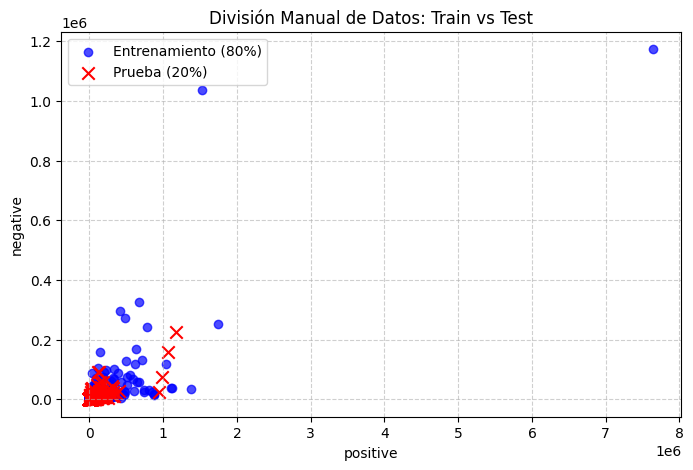

In [132]:
# Visualizar división de datos Train (80%) vs Test (20%)
plt.figure(figsize=(8, 5))
plt.scatter(X_train_s, y_train_s, color='blue', label='Entrenamiento (80%)', alpha=0.7)
plt.scatter(X_test_s, y_test_s, color='red', label='Prueba (20%)', marker='x', s=80)
plt.xlabel('positive')
plt.ylabel('negative')
plt.title('División Manual de Datos: Train vs Test')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [86]:
# Definición de la arquitectura del modelo utilizando nn.Module
class RegresionLinealSimple(nn.Module):
    def __init__(self):
        super(RegresionLinealSimple, self).__init__()
        self.linear = nn.Linear(in_features=1, out_features=1)

    def forward(self, x):
        return self.linear(x)


In [87]:
# Variables de Hiperparámetros separadas
learning_rate_simple = 0.05
epochs_simple = 100

# Instanciación de Modelo y Función de Pérdida MSE
model_simple = RegresionLinealSimple().to(device)
criterion_mse = nn.MSELoss()


In [88]:
# Entrenar el modelo con descenso por gradiente manual (sin optimizador)
loss_history = []

for epoch in range(epochs_simple):
    model_simple.train()

    # Forward pass sobre conjunto de entrenamiento
    y_pred = model_simple(X_train_s_tensor)
    loss = criterion_mse(y_pred, y_train_s_tensor)

    # Backward pass y actualización manual de parámetros
    loss.backward()
    with torch.no_grad():
        for param in model_simple.parameters():
            param -= learning_rate_simple * param.grad
            param.grad.zero_()

    loss_history.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f'Época [{epoch+1}/{epochs_simple}], Pérdida MSE Train: {loss.item():.4f}')


Época [20/100], Pérdida MSE Train: 61122184.0000
Época [40/100], Pérdida MSE Train: 59083508.0000
Época [60/100], Pérdida MSE Train: 59053372.0000
Época [80/100], Pérdida MSE Train: 59052932.0000
Época [100/100], Pérdida MSE Train: 59052924.0000


In [89]:
# Evaluación del modelo sobre el conjunto de Prueba (Test 20%)
model_simple.eval()
with torch.no_grad():
    y_pred_test = model_simple(X_test_s_tensor)
    loss_test_s = criterion_mse(y_pred_test, y_test_s_tensor)

print(f'Pérdida MSE Final en Entrenamiento (Train 80%): {loss_history[-1]:.4f}')
print(f'Pérdida MSE Final en Prueba (Test 20%): {loss_test_s.item():.4f}')


Pérdida MSE Final en Entrenamiento (Train 80%): 59052924.0000
Pérdida MSE Final en Prueba (Test 20%): 13296923.0000


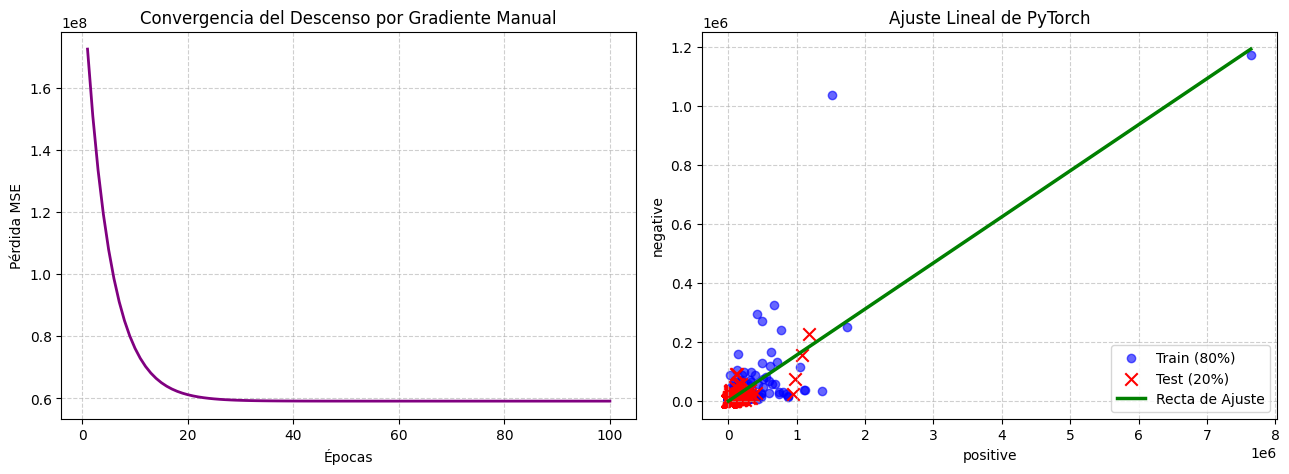

In [90]:
# Gráficas de la curva de costo y la recta de ajuste sobre Train y Test
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Curva de costo
ax1.plot(range(1, epochs_simple + 1), loss_history, color='purple', linewidth=2)
ax1.set_xlabel('Épocas')
ax1.set_ylabel('Pérdida MSE')
ax1.set_title('Convergencia del Descenso por Gradiente Manual')
ax1.grid(True, linestyle='--', alpha=0.6)

# Ajuste Lineal
ax2.scatter(X_train_s, y_train_s, color='blue', alpha=0.6, label='Train (80%)')
ax2.scatter(X_test_s, y_test_s, color='red', marker='x', s=80, label='Test (20%)')

x_range = np.linspace(X_simple.min(), X_simple.max(), 100).reshape(-1, 1)
x_range_norm = (x_range - mu_s) / std_s
x_range_tensor = torch.tensor(x_range_norm, dtype=torch.float32).to(device)
with torch.no_grad():
    y_range_pred = model_simple(x_range_tensor).cpu().numpy()

ax2.plot(x_range, y_range_pred, color='green', linewidth=2.5, label='Recta de Ajuste')
ax2.set_xlabel('positive')
ax2.set_ylabel('negative')
ax2.set_title('Ajuste Lineal de PyTorch')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 4. Regresión Lineal Múltiple, Polinómica y Ecuación de la Normal (Lab 2)
Trabajamos con múltiples características explicativas.
Comparamos:
1. **Regresión Lineal Múltiple** ($nn.Linear(3, 1)$).
2. **Regresión Polinómica** (Añadiendo término cuadrático $x_3^2$).
3. **Ecuación de la Normal** analítica mediante $\hat{\theta} = (X^T X)^{-1} X^T y$ usando `torch.linalg.pinv`.

Todas las evaluaciones se realizan sobre el conjunto de **Prueba (Test 20%)** dividido manualmente.


In [91]:
# Cargar dataset multivariable
data = pd.read_csv('/content/drive/MyDrive/machine learning/laboratorio/regsimple.csv')

df_multi = data
df_multi.head()


,appid,name,developer,publisher,positive,negative,owners,average_forever,average_2weeks,median_forever,...,short_description,supported_languages,platforms_windows,platforms_mac,platforms_linux,metacritic_score,recommendations,achievements,genres,categories
0,730,Counter-Strike: Global Offensive,Valve,Valve,7642084,1173003,"100,000,000 .. 200,000,000",0,0,0,...,"For over two decades, Counter-Strike has offer...","Czech, Danish, Dutch, English<strong>*</strong...",True,False,True,NaN,5211693.0,1.0,"Action, Free To Play","Multi-player, Cross-Platform Multiplayer, Stea..."
1,1172470,Apex Legends,Respawn,Electronic Arts,668053,326926,"100,000,000 .. 200,000,000",0,0,0,...,"Apex Legends is the award-winning, free-to-pla...","English<strong>*</strong>, French<strong>*</st...",True,False,False,88.0,1580.0,12.0,"Action, Adventure, Free To Play","Multi-player, PvP, Online PvP, Co-op, Online C..."
2,578080,PUBG: BATTLEGROUNDS,PUBG Corporation,"KRAFTON, Inc.",1520457,1037487,"100,000,000 .. 200,000,000",0,0,0,...,"PUBG: BATTLEGROUNDS, the high-stakes winner-ta...","English, Korean, Simplified Chinese, French, G...",True,False,False,NaN,1762488.0,37.0,"Action, Adventure, Massively Multiplayer, Free...","Multi-player, PvP, Online PvP, Custom Volume C..."
3,1623730,Palworld,Pocketpair,Pocketpair,358266,22443,"50,000,000 .. 100,000,000",0,0,0,...,"Fight, farm, build and work alongside mysterio...","English, Simplified Chinese, Traditional Chine...",True,False,False,NaN,397504.0,75.0,"Action, Adventure, Indie, RPG","Single-player, Multi-player, Co-op, Online Co-..."
4,440,Team Fortress 2,Valve,Valve,1044264,117208,"50,000,000 .. 100,000,000",0,0,0,...,Nine distinct classes provide a broad range of...,"English<strong>*</strong>, Danish, Dutch, Finn...",True,False,True,92.0,47647.0,520.0,"Action, Free To Play","Multi-player, Cross-Platform Multiplayer, Stea..."


In [92]:
import numpy as np
import torch

df_multi = df_multi.dropna(
    subset=['positive', 'negative', 'recommendations', 'price']
).copy()

# Seleccionar variables


# División Manual de Datos Multivariable (80% Train / 20% Test)
# Seleccionar columnas numéricas relevantes para las características X_m
X_m = df_multi[['positive', 'negative', 'recommendations']].values
y_m = df_multi[['price']].values # Usamos 'price' como objetivo

# Permutación aleatoria manual de índices
np.random.seed(42)
total_m = len(X_m)
train_size_m = int(total_m * 0.8)

indices_m = np.random.permutation(total_m)
train_idx_m = indices_m[:train_size_m]
test_idx_m = indices_m[train_size_m:]

# Indexación manual de conjuntos Train y Test
X_train_m, y_train_m = X_m[train_idx_m], y_m[train_idx_m]
X_test_m, y_test_m = X_m[test_idx_m], y_m[test_idx_m]

# Normalización z-score basada exclusivamente en Train
mu_m, std_m = X_train_m.mean(axis=0), X_train_m.std(axis=0)
# Evitar división por cero si la desviación estándar es cero
std_m[std_m == 0] = 1e-8
X_train_m_norm = (X_train_m - mu_m) / std_m
X_test_m_norm = (X_test_m - mu_m) / std_m

X_train_m_tensor = torch.tensor(X_train_m_norm, dtype=torch.float32).to(device)
y_train_m_tensor = torch.tensor(y_train_m, dtype=torch.float32).to(device)
X_test_m_tensor = torch.tensor(X_test_m_norm, dtype=torch.float32).to(device)
y_test_m_tensor = torch.tensor(y_test_m, dtype=torch.float32).to(device)

print(f'Train Muestras (80%): {len(X_train_m)}, Test Muestras (20%): {len(X_test_m)}')


Train Muestras (80%): 18441, Test Muestras (20%): 4611


In [93]:
# 1. Regresión Lineal Múltiple con actualización manual de gradientes
# Variables de Hiperparámetros separadas
learning_rate_multi = 0.1
epochs_multi = 200

model_multi = nn.Linear(in_features=3, out_features=1).to(device)

for epoch in range(epochs_multi):
    model_multi.train()
    pred = model_multi(X_train_m_tensor)
    loss_m = criterion_mse(pred, y_train_m_tensor)

    loss_m.backward()
    with torch.no_grad():
        for param in model_multi.parameters():
            param -= learning_rate_multi * param.grad
            param.grad.zero_()

model_multi.eval()
with torch.no_grad():
    pred_test_m = model_multi(X_test_m_tensor)
    loss_test_m = criterion_mse(pred_test_m, y_test_m_tensor)

print(f'Regresión Múltiple -> MSE Train: {loss_m.item():.4f} | MSE Test (20%): {loss_test_m.item():.4f}')


Regresión Múltiple -> MSE Train: 1132566.1250 | MSE Test (20%): 1048667.7500


In [94]:
# 2. Regresión Polinómica (Añadir término cuadrático x3^2)
x3_sq_train = (X_train_m_norm[:, 2:3])**2
X_poly_train = np.hstack([X_train_m_norm, x3_sq_train])

x3_sq_test = (X_test_m_norm[:, 2:3])**2
X_poly_test = np.hstack([X_test_m_norm, x3_sq_test])

X_poly_train_tensor = torch.tensor(X_poly_train, dtype=torch.float32).to(device)
X_poly_test_tensor = torch.tensor(X_poly_test, dtype=torch.float32).to(device)

# Variables de Hiperparámetros separadas
learning_rate_poly = 0.0001
epochs_poly = 250

model_poly = nn.Linear(in_features=4, out_features=1).to(device)

for epoch in range(epochs_poly):
    model_poly.train()
    pred_poly = model_poly(X_poly_train_tensor)
    loss_p = criterion_mse(pred_poly, y_train_m_tensor)

    loss_p.backward()
    with torch.no_grad():
        for param in model_poly.parameters():
            param -= learning_rate_poly * param.grad
            param.grad.zero_()

model_poly.eval()
with torch.no_grad():
    pred_poly_test = model_poly(X_poly_test_tensor)
    loss_p_test = criterion_mse(pred_poly_test, y_test_m_tensor)

print(f'Regresión Polinómica -> MSE Train: {loss_p.item():.4f} | MSE Test (20%): {loss_p_test.item():.4f}')



Regresión Polinómica -> MSE Train: 1894248.3750 | MSE Test (20%): 1818153.8750


In [95]:
# 3. Ecuación de la Normal analítica en PyTorch
# Añadir columna de unos (sesgo b) a los tensores de Train y Test
X_b_train = torch.cat([torch.ones((X_train_m_tensor.shape[0], 1), device=device), X_train_m_tensor], dim=1)
X_b_test = torch.cat([torch.ones((X_test_m_tensor.shape[0], 1), device=device), X_test_m_tensor], dim=1)

# θ = (X^T * X)^(-1) * X^T * y
theta_norm = torch.linalg.pinv(X_b_train.T @ X_b_train) @ X_b_train.T @ y_train_m_tensor

# Predicción sobre conjunto de Test (20%)
y_pred_norm_test = X_b_test @ theta_norm
loss_norm_test = criterion_mse(y_pred_norm_test, y_test_m_tensor)

print('Vector de parámetros theta (Ecuación de la Normal):')
print(theta_norm.cpu().numpy())
print(f'MSE Ecuación de la Normal Test (20%): {loss_norm_test.item():.4f}')


Vector de parámetros theta (Ecuación de la Normal):
[[ 905.5497  ]
 [-379.0135  ]
 [ -35.126274]
 [ 485.98364 ]]
MSE Ecuación de la Normal Test (20%): 1046393.8750


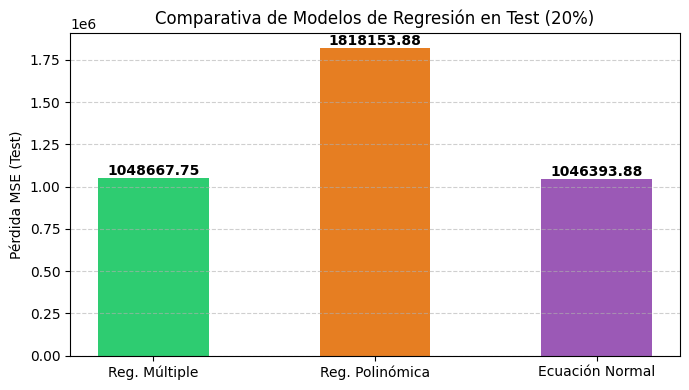

In [96]:
# Gráficas comparativas de errores en el conjunto de Test
plt.figure(figsize=(7, 4))
modelos = ['Reg. Múltiple', 'Reg. Polinómica', 'Ecuación Normal']
mses_test = [loss_test_m.item(), loss_p_test.item(), loss_norm_test.item()]

bars = plt.bar(modelos, mses_test, color=['#2ecc71', '#e67e22', '#9b59b6'], width=0.5)
plt.ylabel('Pérdida MSE (Test)')
plt.title('Comparativa de Modelos de Regresión en Test (20%)')
plt.grid(True, linestyle='--', alpha=0.6, axis='y')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, f'{yval:.2f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


## 5. Regresión Logística Binaria (Lab 3)
Para problemas de clasificación binaria $y \in \{0, 1\}$, aplicamos la función de activación Sigmoide:
$$\sigma(z) = \frac{1}{1 + e^{-z}}$$
Optimizamos utilizando la función de pérdida de Entropía Cruzada Binaria (`nn.BCELoss`) con actualización manual de gradientes.


In [97]:
# Cargar el dataset binario
data = pd.read_csv('/content/drive/MyDrive/machine learning/laboratorio/regsimple.csv')

df_bin = data

df_bin.head()


,appid,name,developer,publisher,positive,negative,owners,average_forever,average_2weeks,median_forever,...,short_description,supported_languages,platforms_windows,platforms_mac,platforms_linux,metacritic_score,recommendations,achievements,genres,categories
0,730,Counter-Strike: Global Offensive,Valve,Valve,7642084,1173003,"100,000,000 .. 200,000,000",0,0,0,...,"For over two decades, Counter-Strike has offer...","Czech, Danish, Dutch, English<strong>*</strong...",True,False,True,NaN,5211693.0,1.0,"Action, Free To Play","Multi-player, Cross-Platform Multiplayer, Stea..."
1,1172470,Apex Legends,Respawn,Electronic Arts,668053,326926,"100,000,000 .. 200,000,000",0,0,0,...,"Apex Legends is the award-winning, free-to-pla...","English<strong>*</strong>, French<strong>*</st...",True,False,False,88.0,1580.0,12.0,"Action, Adventure, Free To Play","Multi-player, PvP, Online PvP, Co-op, Online C..."
2,578080,PUBG: BATTLEGROUNDS,PUBG Corporation,"KRAFTON, Inc.",1520457,1037487,"100,000,000 .. 200,000,000",0,0,0,...,"PUBG: BATTLEGROUNDS, the high-stakes winner-ta...","English, Korean, Simplified Chinese, French, G...",True,False,False,NaN,1762488.0,37.0,"Action, Adventure, Massively Multiplayer, Free...","Multi-player, PvP, Online PvP, Custom Volume C..."
3,1623730,Palworld,Pocketpair,Pocketpair,358266,22443,"50,000,000 .. 100,000,000",0,0,0,...,"Fight, farm, build and work alongside mysterio...","English, Simplified Chinese, Traditional Chine...",True,False,False,NaN,397504.0,75.0,"Action, Adventure, Indie, RPG","Single-player, Multi-player, Co-op, Online Co-..."
4,440,Team Fortress 2,Valve,Valve,1044264,117208,"50,000,000 .. 100,000,000",0,0,0,...,Nine distinct classes provide a broad range of...,"English<strong>*</strong>, Danish, Dutch, Finn...",True,False,True,92.0,47647.0,520.0,"Action, Free To Play","Multi-player, Cross-Platform Multiplayer, Stea..."


In [98]:
# División Manual de Datos Binarios (80% Train / 20% Test)
#X_bin = df_bin.drop(columns=['gama_alta']).values
#y_bin = df_bin['gama_alta'].values.reshape(-1, 1)

# Seleccionar columnas numéricas útiles
columnas = ['positive', 'negative', 'metacritic_score', 'achievements', 'price']
df_clean = df_bin[columnas].dropna().copy()

# --- CREAR LA VARIABLE OBJETIVO BINARIA ---
# Definimos "gama_alta" o "exitoso": 1 si tiene precio mayor a $20, 0 si no
# (Puedes cambiar la regla, por ejemplo: df_clean['positive'] > 1000)
df_clean['gama_alta'] = (df_clean['price'] > 10000.0).astype(int)

X_bin = df_clean[['positive', 'negative', 'metacritic_score', 'achievements']].values
y_bin = df_clean['gama_alta'].values.reshape(-1, 1)

# Permutación aleatoria manual de índices
np.random.seed(42)
total_b = len(X_bin)
train_size_b = int(total_b * 0.8)

indices_b = np.random.permutation(total_b)
train_idx_b = indices_b[:train_size_b]
test_idx_b = indices_b[train_size_b:]

X_train_b, y_train_b = X_bin[train_idx_b], y_bin[train_idx_b]
X_test_b, y_test_b = X_bin[test_idx_b], y_bin[test_idx_b]

mu_b, std_b = X_train_b.mean(axis=0), X_train_b.std(axis=0)
# Evitar división por cero si la desviación estándar es cero
std_b[std_b == 0] = 1e-8
X_train_b_norm = (X_train_b - mu_b) / std_b
X_test_b_norm = (X_test_b - mu_b) / std_b

X_train_b_tensor = torch.tensor(X_train_b_norm, dtype=torch.float32).to(device)
y_train_b_tensor = torch.tensor(y_bin[train_idx_b], dtype=torch.float32).to(device) # Usar y_bin[train_idx_b] en vez de y_train_b
X_test_b_tensor = torch.tensor(X_test_b_norm, dtype=torch.float32).to(device)
y_test_b_tensor = torch.tensor(y_bin[test_idx_b], dtype=torch.float32).to(device) # Usar y_bin[test_idx_b] en vez de y_test_b

print(f'Train Binario (80%): {len(X_train_b)}, Test Binario (20%): {len(X_test_b)}')


print(df_clean[['price', 'gama_alta']].head(100))


Train Binario (80%): 2964, Test Binario (20%): 742
     price  gama_alta
1        0          0
4        0          0
8        0          0
9      999          0
12       0          0
..     ...        ...
170    999          0
172    999          0
175   1999          0
177   3999          0
178   2999          0

[100 rows x 2 columns]


In [99]:
# Definición de la arquitectura Logística Binaria
class RegresionLogisticaBinaria(nn.Module):
    def __init__(self, in_features):
        super(RegresionLogisticaBinaria, self).__init__()
        self.linear = nn.Linear(in_features, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        return self.sigmoid(self.linear(x))


In [100]:
# Variables de Hiperparámetros separadas
learning_rate_bin = 0.5
epochs_bin = 250

# Instanciación de Modelo y Pérdida
model_bin = RegresionLogisticaBinaria(in_features=4).to(device)
criterion_bce = nn.BCELoss()

# Entrenamiento binario (descenso por gradiente manual)
for epoch in range(epochs_bin):
    model_bin.train()
    probs = model_bin(X_train_b_tensor)
    loss_bin = criterion_bce(probs, y_train_b_tensor)

    loss_bin.backward()
    with torch.no_grad():
        for param in model_bin.parameters():
            param -= learning_rate_bin * param.grad
            param.grad.zero_()

print(f'Pérdida final BCE Train: {loss_bin.item():.4f}')


Pérdida final BCE Train: 0.0082


In [101]:
# Evaluación de la exactitud (Accuracy) en el conjunto de Prueba (Test 20%)
model_bin.eval()
with torch.no_grad():
    probs_test = model_bin(X_test_b_tensor).cpu().numpy()
    y_pred_bin_test = (probs_test >= 0.5).astype(int)

acc_bin_test = accuracy_score(y_test_b, y_pred_bin_test)
print(f'Exactitud en Test (Accuracy 20%): {acc_bin_test * 100:.2f}%')


Exactitud en Test (Accuracy 20%): 100.00%


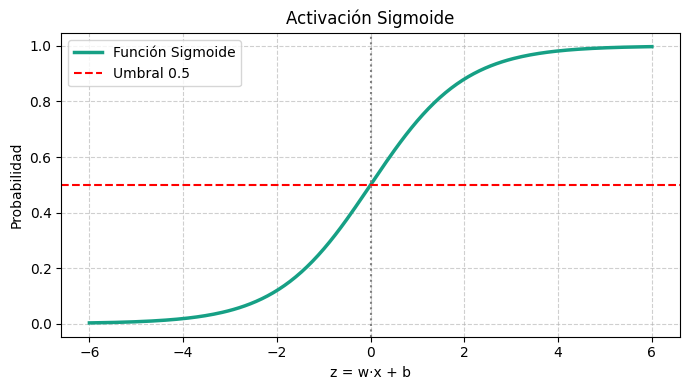

In [102]:
# Gráfica de la función de activación Sigmoide
plt.figure(figsize=(7, 4))
z = np.linspace(-6, 6, 200)
sig = 1 / (1 + np.exp(-z))
plt.plot(z, sig, color='#16a085', linewidth=2.5, label='Función Sigmoide')
plt.axhline(0.5, color='red', linestyle='--', label='Umbral 0.5')
plt.axvline(0, color='gray', linestyle=':')
plt.xlabel('z = w·x + b')
plt.ylabel('Probabilidad')
plt.title('Activación Sigmoide')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## 6. Clasificación Multiclase (Lab 4)
Para clasificar en $K$ clases comparamos dos estrategias:
1. **One-vs-All**: Ensamble de $K$ clasificadores binarios independientes (`nn.BCELoss`).
2. **Softmax / CrossEntropy Nativo**: Modelo multiclase directo (`nn.CrossEntropyLoss`).


In [103]:
# Cargar el dataset multiclase
df_multi_cls = pd.read_csv('/content/drive/MyDrive/machine learning/laboratorio/lab004.csv')

df_multi_cls.head()


,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,...,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,...,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,...,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,...,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,...,0.0,2.981470e+07,2.981470e+07,2.981470e+07,2.981470e+07,0.0,64240,26847,502,MQTT_Publish


In [104]:
from sklearn.preprocessing import LabelEncoder

# 2. Separar características (X) y la etiqueta multiclase (y)
# 'Attack_type' contiene los diferentes tipos de ataques y tráfico normal
target_col = 'Attack_type'

# Filtramos solo columnas numéricas para X (excluyendo id, ip o columnas de texto si las hay)
X_raw = df_multi_cls.drop(columns=[target_col]).select_dtypes(include=[np.number]).values
y_raw = df_multi_cls[target_col].values

# 3. Codificar las etiquetas de texto a números (0, 1, ..., K-1)
label_encoder = LabelEncoder()
y_mc = label_encoder.fit_transform(y_raw)
X_mc = X_raw

# División Manual de Datos Multiclase (80% Train / 20% Test)
#X_mc = df_multi_cls.drop(columns=['tipo_semilla']).values
#y_mc = df_multi_cls['tipo_semilla'].values

# Permutación aleatoria manual de índices
np.random.seed(42)
total_mc = len(X_mc)
train_size_mc = int(total_mc * 0.8)

indices_mc = np.random.permutation(total_mc)
train_idx_mc = indices_mc[:train_size_mc]
test_idx_mc = indices_mc[train_size_mc:]

X_train_mc, y_train_mc = X_mc[train_idx_mc], y_mc[train_idx_mc]
X_test_mc, y_test_mc = X_mc[test_idx_mc], y_mc[test_idx_mc]

mu_mc, std_mc = X_train_mc.mean(axis=0), X_train_mc.std(axis=0)
# Evitar división por cero si la desviación estándar es cero
std_mc[std_mc == 0] = 1e-8
X_train_mc_norm = (X_train_mc - mu_mc) / std_mc
X_test_mc_norm = (X_test_mc - mu_mc) / std_mc

X_train_mc_tensor = torch.tensor(X_train_mc_norm, dtype=torch.float32).to(device)
y_train_mc_tensor = torch.tensor(y_train_mc, dtype=torch.long).to(device)
X_test_mc_tensor = torch.tensor(X_test_mc_norm, dtype=torch.float32).to(device)
y_test_mc_tensor = torch.tensor(y_test_mc, dtype=torch.long).to(device)

num_classes = len(np.unique(y_mc))
num_features = X_mc.shape[1]

print(f'Características: {num_features}, Clases K: {num_classes}')
print(f'Train Multiclase (80%): {len(X_train_mc)}, Test Multiclase (20%): {len(X_test_mc)}')


Características: 82, Clases K: 12
Train Multiclase (80%): 98493, Test Multiclase (20%): 24624


In [105]:
# Entrenamiento de K clasificadores binarios (One-vs-All) con gradiente manual
# Variables de Hiperparámetros separadas
learning_rate_ova = 0.5
epochs_ova = 250

classifiers = []

for k in range(num_classes):
    y_k_train = (y_train_mc == k).astype(np.float32).reshape(-1, 1)
    y_k_tensor = torch.tensor(y_k_train, dtype=torch.float32).to(device)

    model_k = RegresionLogisticaBinaria(in_features=num_features).to(device)
    criterion_k = nn.BCELoss()

    for _ in range(epochs_ova):
        model_k.train()
        pred = model_k(X_train_mc_tensor)
        loss_k = criterion_k(pred, y_k_tensor)

        loss_k.backward()
        with torch.no_grad():
            for param in model_k.parameters():
                param -= learning_rate_ova * param.grad
                param.grad.zero_()

    classifiers.append(model_k)


In [106]:
# Predicción y evaluación One-vs-All sobre el conjunto de Test (20%)
all_probs_test = []
for clf in classifiers:
    clf.eval()
    with torch.no_grad():
        all_probs_test.append(clf(X_test_mc_tensor).cpu().numpy())

all_probs_test = np.hstack(all_probs_test)
preds_ova_test = np.argmax(all_probs_test, axis=1)

acc_ova_test = accuracy_score(y_test_mc, preds_ova_test)
print(f'Exactitud One-vs-All en Test 20%: {acc_ova_test * 100:.2f}%')


Exactitud One-vs-All en Test 20%: 97.15%


In [107]:
# Definición del modelo multiclase nativo
class ClasificadorMulticlase(nn.Module):
    def __init__(self, in_features, num_classes):
        super(ClasificadorMulticlase, self).__init__()
        self.linear = nn.Linear(in_features, num_classes)

    def forward(self, x):
        return self.linear(x)


In [108]:
# Entrenamiento multiclase nativo (CrossEntropyLoss) con gradiente manual
# Variables de Hiperparámetros separadas
learning_rate_native = 0.5
epochs_native = 250

# Instanciación del Modelo y Pérdida
model_native = ClasificadorMulticlase(num_features, num_classes).to(device)
criterion_ce = nn.CrossEntropyLoss()

for epoch in range(epochs_native):
    model_native.train()
    logits = model_native(X_train_mc_tensor)
    loss_ce = criterion_ce(logits, y_train_mc_tensor)

    loss_ce.backward()
    with torch.no_grad():
        for param in model_native.parameters():
            param -= learning_rate_native * param.grad
            param.grad.zero_()

print(f'Pérdida final CrossEntropy Train: {loss_ce.item():.4f}')


Pérdida final CrossEntropy Train: 0.0884


In [109]:
# Predicción y evaluación multiclase nativa sobre el conjunto de Test (20%)
model_native.eval()
with torch.no_grad():
    logits_test = model_native(X_test_mc_tensor)
    preds_native_test = torch.argmax(logits_test, dim=1).cpu().numpy()

acc_native_test = accuracy_score(y_test_mc, preds_native_test)
print(f'Exactitud Multiclase Nativo en Test 20%: {acc_native_test * 100:.2f}%')


Exactitud Multiclase Nativo en Test 20%: 97.84%


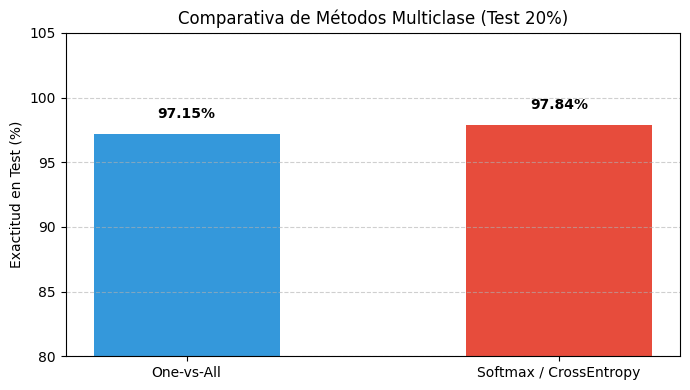

In [110]:
# Gráfica comparativa de Métodos Multiclase en Test (20%)
plt.figure(figsize=(7, 4))
metodos = ['One-vs-All', 'Softmax / CrossEntropy']
exactitudes = [acc_ova_test * 100, acc_native_test * 100]

bars = plt.bar(metodos, exactitudes, color=['#3498db', '#e74c3c'], width=0.5)
plt.ylabel('Exactitud en Test (%)')
plt.ylim(80, 105)
plt.title('Comparativa de Métodos Multiclase (Test 20%)')
plt.grid(True, linestyle='--', alpha=0.6, axis='y')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1.0, f'{yval:.2f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


LABORATORIO 5

In [118]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


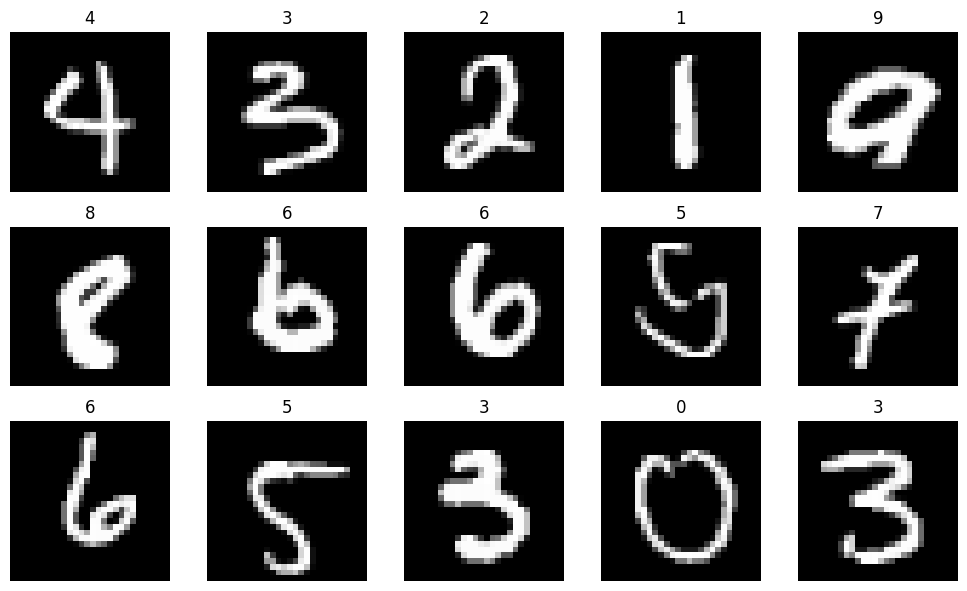

Dimensiones Train: (8000, 784), Dimensiones Test: (2000, 784)


In [126]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

# 1. Cargar el dataset lab05 desde tu Google Drive
path = '/content/drive/MyDrive/machine learning/laboratorio/lab05'
df = pd.read_csv(path)

# 2. Separar características (X) y etiqueta objetivo (y)
X = df.drop(columns=['label']).values.astype(np.float32) / 255.0
y = df['label'].values.astype(np.int64)

# 3. División manual 80% Train / 20% Test
train_size = int(len(X) * 0.8)

X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

# 4. Visualización aleatoria de 15 imágenes de entrenamiento
r, c = 3, 5
fig = plt.figure(figsize=(2*c, 2*r))
for _r in range(r):
    for _c in range(c):
        plt.subplot(r, c, _r*c + _c + 1)
        ix = random.randint(0, len(X_train) - 1)
        img = X_train[ix]
        plt.imshow(img.reshape(28, 28), cmap='gray')
        plt.axis("off")
        plt.title(y_train[ix])
plt.tight_layout()
plt.show()

print(f"Dimensiones Train: {X_train.shape}, Dimensiones Test: {X_test.shape}")

In [127]:
# Función Softmax para convertir logits a probabilidades acotadas entre 0 y 1
def softmax(x):
    return torch.exp(x) / torch.exp(x).sum(axis=-1, keepdims=True)

# Función de costo de Entropía Cruzada
def cross_entropy(output, target):
    logits = output[torch.arange(len(output)), target]
    loss = - logits + torch.log(torch.sum(torch.exp(output), axis=-1))
    loss = loss.mean()
    return loss

In [128]:

# Dimensiones de la red
D_in, H, D_out = 784, 100, 10

# Determinar dispositivo (usa GPU si está disponible)
device = "cuda" if torch.cuda.is_available() else "cpu"

# Pesos y sesgos de la Capa Oculta (W1, b1)
w1 = torch.tensor(np.random.normal(loc=0.0,
                                   scale=np.sqrt(2/(D_in+H)),
                                   size=(D_in, H)), requires_grad=True, device=device, dtype=torch.float)
b1 = torch.zeros(H, requires_grad=True, device=device, dtype=torch.float)

# Pesos y sesgos de la Capa de Salida (W2, b2)
w2 = torch.tensor(np.random.normal(loc=0.0,
                                   scale=np.sqrt(2/(D_out+H)),
                                   size=(H, D_out)), requires_grad=True, device=device, dtype=torch.float)
b2 = torch.zeros(D_out, requires_grad=True, device=device, dtype=torch.float)

# Convertir datos de entrenamiento a tensores en la GPU/CPU
X_t = torch.from_numpy(X_train).float().to(device)
Y_t = torch.from_numpy(y_train).long().to(device)

In [129]:

epochs = 100
lr = 0.8  # Tasa de aprendizaje (alpha)
log_each = 10
l = []

for e in range(1, epochs + 1):

    # --- FORWARD PASS ---
    h = X_t.mm(w1) + b1
    h_relu = h.clamp(min=0)  # Activación ReLU
    y_pred = h_relu.mm(w2) + b2  # Logits de salida

    # --- LOSS ---
    loss = cross_entropy(y_pred, Y_t)
    l.append(loss.item())

    # --- BACKPROPAGATION ---
    loss.backward()

    # --- ACTUALIZACIÓN DE PARÁMETROS (Gradiente Descendente Manual) ---
    with torch.no_grad():
        w1 -= lr * w1.grad
        b1 -= lr * b1.grad
        w2 -= lr * w2.grad
        b2 -= lr * b2.grad

        # Reiniciar los gradientes a cero para evitar acumulación
        w1.grad.zero_()
        b1.grad.zero_()
        w2.grad.zero_()
        b2.grad.zero_()

    if not e % log_each:
        print(f"Epoch {e}/{epochs} Loss {np.mean(l):.5f}")

Epoch 10/100 Loss 1.64837
Epoch 20/100 Loss 1.33194
Epoch 30/100 Loss 1.07984
Epoch 40/100 Loss 0.90183
Epoch 50/100 Loss 0.81370
Epoch 60/100 Loss 0.72433
Epoch 70/100 Loss 0.65540
Epoch 80/100 Loss 0.60123
Epoch 90/100 Loss 0.55760
Epoch 100/100 Loss 0.52265


In [130]:
from sklearn.metrics import accuracy_score

def evaluate(x):
    h = x.mm(w1) + b1
    h_relu = h.clamp(min=0)
    y_pred = h_relu.mm(w2) + b2
    y_probas = softmax(y_pred)
    return torch.argmax(y_probas, axis=1)

# Evaluar en el conjunto de prueba
X_test_tensor = torch.from_numpy(X_test).float().to(device)
y_pred_test = evaluate(X_test_tensor)

acc = accuracy_score(y_test, y_pred_test.cpu().numpy())
print(f"\nPrecisión final en Test (Accuracy): {acc * 100:.2f}%")


Precisión final en Test (Accuracy): 94.25%


/tmp/ipykernel_874/724475800.py:11: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  img_tensor = torch.tensor([img]).float().to(device)


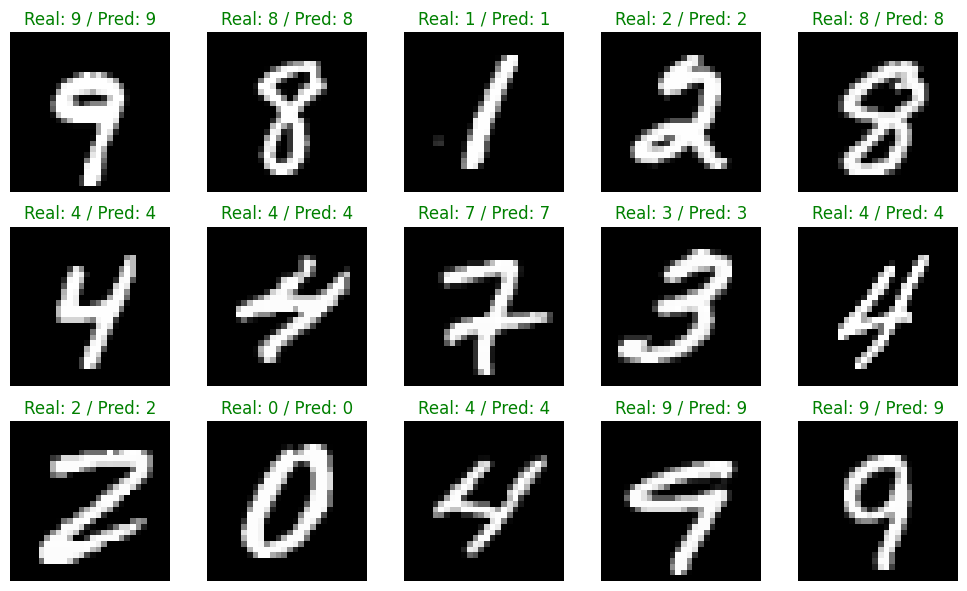

In [131]:
r, c = 3, 5
fig = plt.figure(figsize=(2*c, 2*r))

for _r in range(r):
    for _c in range(c):
        plt.subplot(r, c, _r*c + _c + 1)
        ix = random.randint(0, len(X_test) - 1)
        img = X_test[ix]

        # Inferencia de una sola imagen
        img_tensor = torch.tensor([img]).float().to(device)
        pred_label = evaluate(img_tensor)[0].item()
        true_label = y_test[ix]

        plt.imshow(img.reshape(28, 28), cmap='gray')
        plt.axis("off")
        plt.title(f"Real: {true_label} / Pred: {pred_label}",
                  color="green" if true_label == pred_label else "red")

plt.tight_layout()
plt.show()